# LoRA Adapter Swap Optimization — Results Analysis

This notebook loads the sweep CSV produced by `experiments/run_sweep.py` and generates:
1. Cost ratio (Gurobi vs Simulated Annealing) across problem sizes
2. Solver wall time vs instance size
3. Per-component cost breakdown (latency / swap / priority)

Run `python experiments/run_sweep.py` before opening this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
from pathlib import Path

SWEEP_CSV = Path("../results/sweep.csv")
OUT_DIR   = Path("../results/charts")
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(SWEEP_CSV)
print(f"Loaded {len(df)} rows  |  solvers: {df['solver'].unique()}")
df.head()

Loaded 38 rows  |  solvers: <StringArray>
['gurobi', 'simulated_annealing']
Length: 2, dtype: str


,seed,sweep_param,sweep_value,solver,total,latency,swap,priority,mip_gap,wall_time
0,42,n_requests,50,gurobi,151.3299,51.8343,23.7987,103.7964,0.000000,0.054500
1,42,n_requests,50,simulated_annealing,745.2994,57.0929,315.6944,113.6354,0.000000,0.522543
2,123,n_requests,50,gurobi,140.9154,49.3590,19.7084,104.2790,0.006653,0.019926
3,123,n_requests,50,simulated_annealing,598.9588,50.4456,247.5213,106.9414,0.000000,0.537582
4,7,n_requests,50,gurobi,152.1369,49.3971,25.2595,104.4416,0.001515,0.019999


## 1. Cost ratio: Gurobi vs Simulated Annealing

For each (sweep_param, sweep_value, seed) cell we compute:

```
gap% = (SA_total - Gurobi_total) / Gurobi_total * 100
```

A positive value means SA is worse than Gurobi by that percentage.

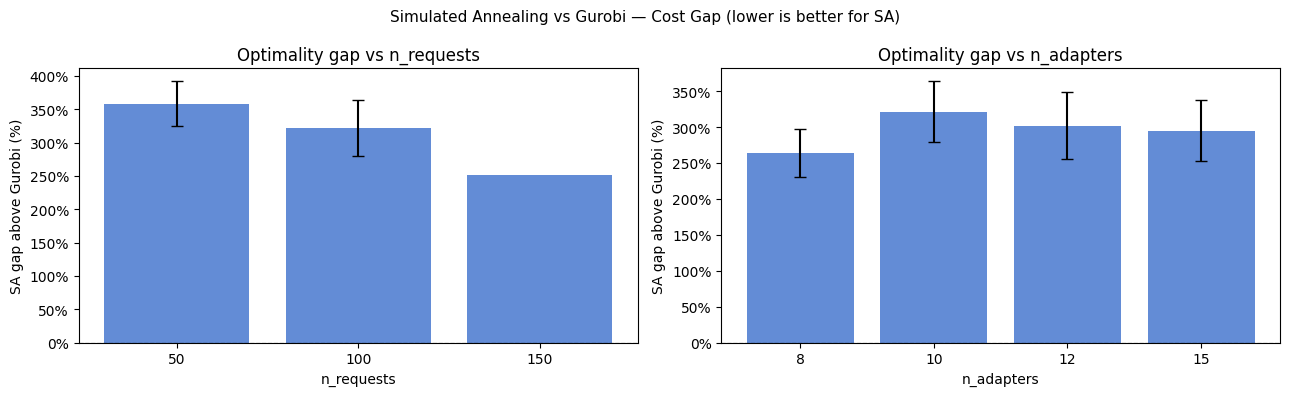

Mean gap across all cells: 307.1%


In [2]:
gurobi = df[df.solver == "gurobi"].set_index(["seed", "sweep_param", "sweep_value"])
sa     = df[df.solver == "simulated_annealing"].set_index(["seed", "sweep_param", "sweep_value"])

ratio = sa[["total"]].join(gurobi[["total"]], lsuffix="_sa", rsuffix="_gurobi")
ratio["gap_pct"] = (ratio["total_sa"] - ratio["total_gurobi"]) / ratio["total_gurobi"] * 100
ratio = ratio.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

for ax, param in zip(axes, ["n_requests", "n_adapters"]):
    sub = ratio[ratio.sweep_param == param]
    agg = sub.groupby("sweep_value")["gap_pct"].agg(["mean", "std"]).reset_index()
    ax.bar(agg["sweep_value"].astype(str), agg["mean"], yerr=agg["std"],
           capsize=4, color="#4878CF", alpha=0.85)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_xlabel(param)
    ax.set_ylabel("SA gap above Gurobi (%)")
    ax.set_title(f"Optimality gap vs {param}")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())

fig.suptitle("Simulated Annealing vs Gurobi — Cost Gap (lower is better for SA)", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "gap_vs_size.png", dpi=150)
plt.show()
print(f"Mean gap across all cells: {ratio['gap_pct'].mean():.1f}%")

## 2. Solver wall time vs instance size

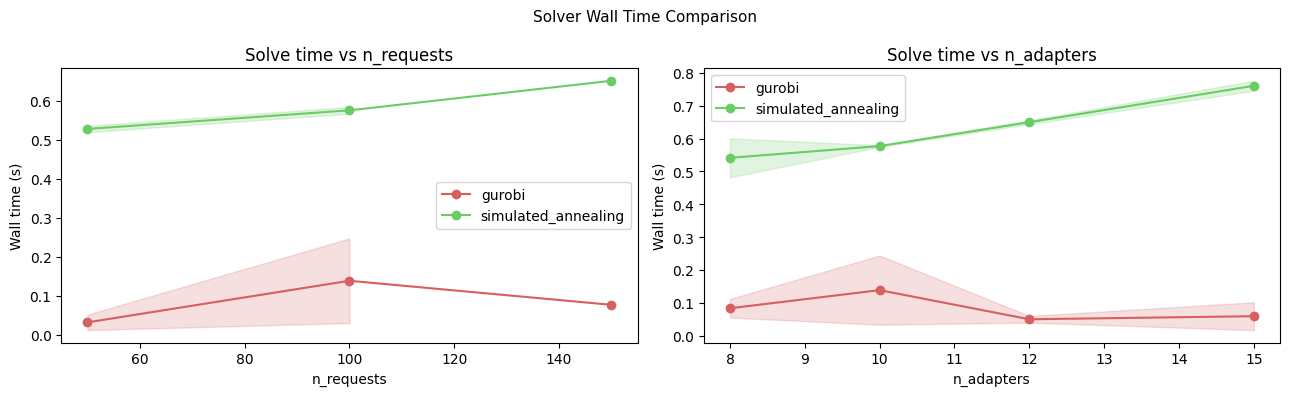

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

colors = {"gurobi": "#D65F5F", "simulated_annealing": "#6ACC65"}

for ax, param in zip(axes, ["n_requests", "n_adapters"]):
    for solver, grp in df.groupby("solver"):
        sub = grp[grp.sweep_param == param]
        agg = sub.groupby("sweep_value")["wall_time"].agg(["mean", "std"]).reset_index()
        ax.plot(agg["sweep_value"], agg["mean"], marker="o",
                label=solver, color=colors[solver])
        ax.fill_between(
            agg["sweep_value"],
            (agg["mean"] - agg["std"]).clip(0),
            agg["mean"] + agg["std"],
            alpha=0.2, color=colors[solver]
        )
    ax.set_xlabel(param)
    ax.set_ylabel("Wall time (s)")
    ax.set_title(f"Solve time vs {param}")
    ax.legend()

fig.suptitle("Solver Wall Time Comparison", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "wall_time_vs_size.png", dpi=150)
plt.show()

## 3. Per-component cost breakdown

Shows how much of the total cost comes from latency, swap overhead, and priority penalty for each solver across problem sizes.

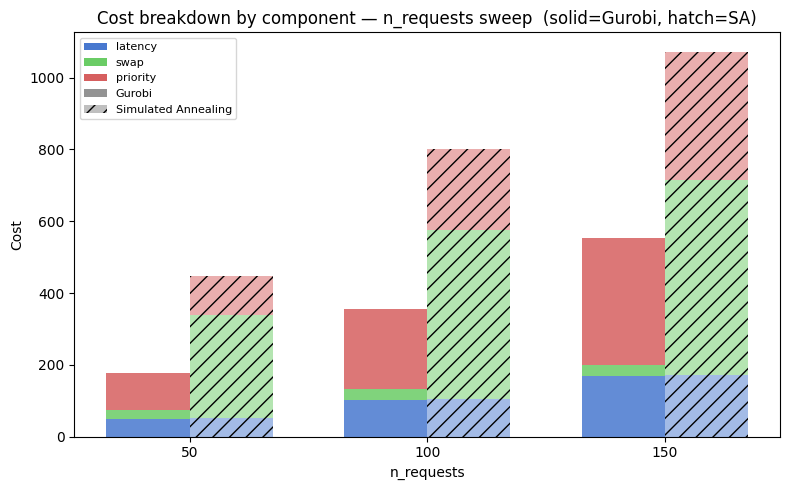

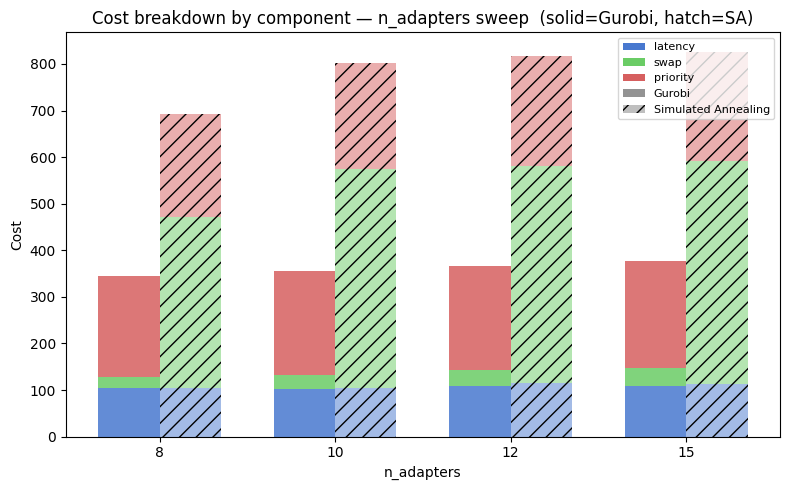

In [4]:
components = ["latency", "swap", "priority"]
comp_colors = {"latency": "#4878CF", "swap": "#6ACC65", "priority": "#D65F5F"}

for param in ["n_requests", "n_adapters"]:
    sub = df[df.sweep_param == param]
    agg = sub.groupby(["sweep_value", "solver"])[components].mean().reset_index()

    values = sorted(agg["sweep_value"].unique())
    solvers = ["gurobi", "simulated_annealing"]
    x = np.arange(len(values))
    width = 0.35

    fig, ax = plt.subplots(figsize=(max(8, len(values) * 2), 5))

    for s_idx, solver in enumerate(solvers):
        s_data = agg[agg.solver == solver].set_index("sweep_value").reindex(values)
        bottoms = np.zeros(len(values))
        for comp in components:
            vals = s_data[comp].fillna(0).values
            ax.bar(
                x + s_idx * width, vals, width,
                bottom=bottoms,
                label=f"{solver}/{comp}" if s_idx == 0 else f"_{comp}",
                color=comp_colors[comp],
                alpha=0.85 if solver == "gurobi" else 0.5,
                hatch="" if solver == "gurobi" else "//",
            )
            bottoms += vals

    ax.set_xticks(x + width / 2)
    ax.set_xticklabels(values)
    ax.set_xlabel(param)
    ax.set_ylabel("Cost")
    ax.set_title(f"Cost breakdown by component — {param} sweep  (solid=Gurobi, hatch=SA)")

    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=comp_colors[c], label=c) for c in components]
    legend_elements += [
        Patch(facecolor="grey", alpha=0.85, label="Gurobi"),
        Patch(facecolor="grey", alpha=0.5, hatch="//", label="Simulated Annealing"),
    ]
    ax.legend(handles=legend_elements, fontsize=8)

    plt.tight_layout()
    plt.savefig(OUT_DIR / f"cost_components_{param}.png", dpi=150)
    plt.show()

## 4. Summary table

In [5]:
summary = (
    df.groupby("solver")[["total", "latency", "swap", "priority", "wall_time"]]
    .agg(["mean", "std"])
    .round(3)
)
print("=== Overall averages across all sweep cells ===")
print(summary.to_string())

mean_gap = ratio["gap_pct"].mean()
median_gap = ratio["gap_pct"].median()
print(f"\nSA optimality gap — mean: {mean_gap:.1f}%  median: {median_gap:.1f}%")

=== Overall averages across all sweep cells ===
                        total           latency             swap         priority         wall_time       
                         mean      std     mean     std     mean     std     mean     std      mean    std
solver                                                                                                    
gurobi                265.779   62.006  100.207  26.951   30.081   5.830  210.818  56.431     0.083  0.068
simulated_annealing  1069.892  234.753  102.783  27.231  429.272  95.453  217.130  57.153     0.608  0.083

SA optimality gap — mean: 307.1%  median: 306.5%
